In [1]:
## conda activate scanpy_3.12
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import sys
import scipy
sys.version
import sys
sys.path.append("/data1/peerd/blattms/materials_2023/session-3/")
import run_MAGIC

import pickle
# Load color palette
with open('/home/blattms1/projects/gapfill/patient_JAK2/20250318_patient_4plex/cell_type_palette.pkl', 'rb') as f:
    cell_type_palette = pickle.load(f)

In [2]:
samples = ['CD34_Day0_Multi_filtered_feature_bc_matrix.h5','CD34_Day7_Ery_filtered_feature_bc_matrix.h5','CD34_Day7_Mega_filtered_feature_bc_matrix.h5','CD34_Day7_Mono_filtered_feature_bc_matrix.h5']

adata_dir = '/data1/lareauc/projects/trnaseq/20250624_Experiment17_CD34culture/cd34_day07_cellranger/outs/per_sample_outs/'

adatas = []
for sample in samples:
    adatas.append(sc.read_10x_h5(adata_dir + sample))


In [3]:
adata = sc.concat(adatas, label='Sample', keys=['Day0','Day7_Ery','Day7_Mega','Day7_Mono'], index_unique='-')


In [4]:
adata

AnnData object with n_obs × n_vars = 76245 × 18099
    obs: 'Sample'

In [5]:
sc.pp.calculate_qc_metrics(adata, inplace = True)
adata

AnnData object with n_obs × n_vars = 76245 × 18099
    obs: 'Sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

In [6]:
min_counts = 1000
min_genes = 500
max_genes = 10000


Text(0.5, 1.0, 'Correlation = 0.975')

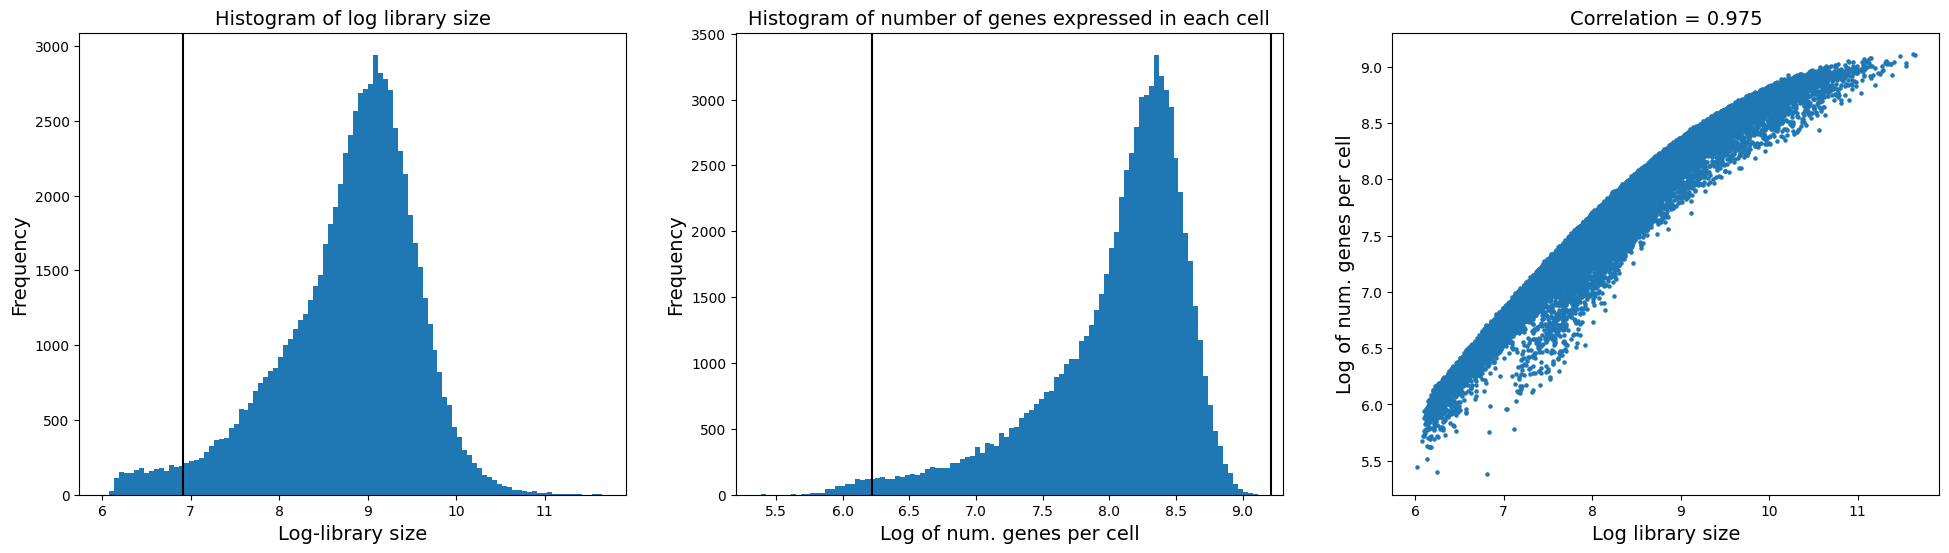

In [7]:
fig = plt.figure(figsize = (8*3, 6*1))
ax = fig.add_subplot(1, 3, 1)
ax.hist(adata.obs['log1p_total_counts'], bins = 100);
ax.set_xlabel('Log-library size', fontsize = 14)
ax.set_ylabel('Frequency', fontsize = 14)
ax.set_title('Histogram of log library size', fontsize = 14)
ax.axvline(np.log1p(min_counts),color='k')

ax = fig.add_subplot(1, 3, 2)
ax.hist(adata.obs['log1p_n_genes_by_counts'], bins = 100);
ax.set_xlabel('Log of num. genes per cell', fontsize = 14)
ax.set_ylabel('Frequency', fontsize = 14)
ax.set_title('Histogram of number of genes expressed in each cell', fontsize = 14)
ax.axvline(np.log1p(min_genes),color='k')
ax.axvline(np.log1p(max_genes),color='k')

ax = fig.add_subplot(1, 3, 3)
x = adata.obs['log1p_total_counts']
y = adata.obs['log1p_n_genes_by_counts']
ax.scatter(x, y, s = 5);
ax.set_ylabel('Log of num. genes per cell', fontsize = 14)
ax.set_xlabel('Log library size', fontsize = 14)
corr_coef = np.corrcoef(x, y)[0, 1]
ax.set_title('Correlation = ' + str(round(corr_coef, 3)), fontsize = 14)



Index(['MT-ND1', 'MT-ND2', 'MT-CO2', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L',
       'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='object')


Text(0, 0.5, '% MT-content')

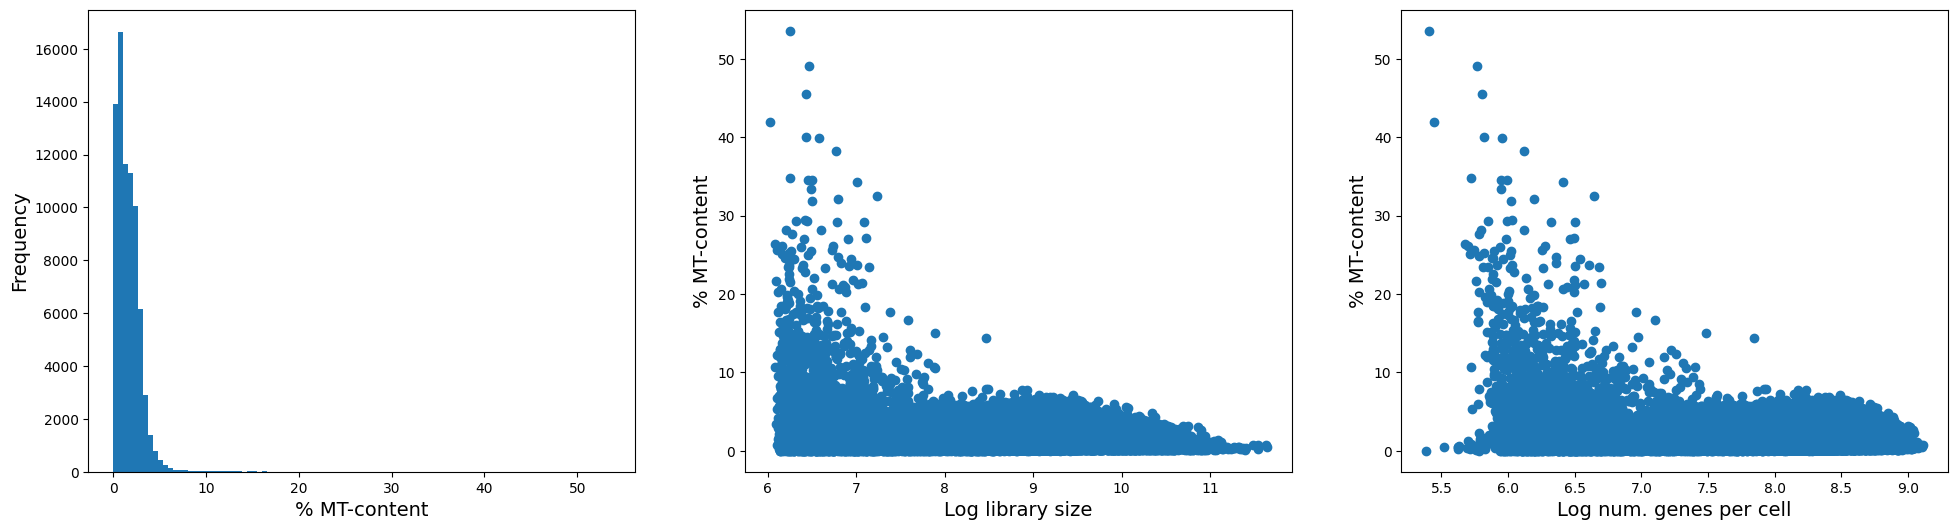

In [8]:
# Identify MT-genes
mito_genes = adata.var_names[adata.var_names.str.startswith('MT-')]
print(mito_genes)
index_mito_genes = [adata.var_names.get_loc(j) for j in mito_genes]
mito_frac = np.asarray(np.sum(adata.X[:, index_mito_genes], axis = 1)/np.sum(adata.X, axis = 1)).squeeze() * 100
adata.obs['mito_frac'] = mito_frac
fig = plt.figure(figsize = (8*3, 6*1))
ax = fig.add_subplot(1, 3, 1)
ax.hist(adata.obs['mito_frac'], 100);
ax.set_xlabel('% MT-content', fontsize = 14)
ax.set_ylabel('Frequency', fontsize = 14)

ax = fig.add_subplot(1, 3, 2)
ax.scatter(adata.obs['log1p_total_counts'], adata.obs['mito_frac']);
ax.set_xlabel('Log library size', fontsize = 14)
ax.set_ylabel('% MT-content', fontsize = 14)

ax = fig.add_subplot(1, 3, 3)
ax.scatter(adata.obs['log1p_n_genes_by_counts'], adata.obs['mito_frac']);
ax.set_xlabel('Log num. genes per cell', fontsize = 14)
ax.set_ylabel('% MT-content', fontsize = 14)


In [9]:
mito_threshold = 10
id_low_mt_cells = adata.obs.index[adata.obs['mito_frac'] < mito_threshold]
print(sum(mito_frac < mito_threshold))
print(len(id_low_mt_cells))
print(len(adata))

adata = adata[id_low_mt_cells, ]


75952
75952
76245


In [10]:
import celltypist
from celltypist import models

adata.layers['raw_data'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum = 10000, inplace = True)
adata.X = np.log1p(adata.X)
sc.pp.highly_variable_genes(adata, layer = 'raw_data', n_top_genes = 4000, flavor = 'seurat_v3')

sc.tl.pca(adata, n_comps=100, use_highly_variable=True)

model = '12_celltypist_adult_control_model_minor_anno2.pkl'
predictions = celltypist.annotate(adata, model = model, majority_voting = False)

adata.obs['PBMC_cell_types'] = predictions.predicted_labels['predicted_labels']
adata.obs['PBMC_cell_types'].value_counts(normalize=True)

🔬 Input data has 75952 cells and 18099 genes
🔗 Matching reference genes in the model
🧬 2205 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


PBMC_cell_types
CD8 Memory        0.435380
HSPC              0.276293
cDC               0.236333
CD16 Monocytes    0.023146
CD14 Monocytes    0.010204
NK                0.006293
CD8 Naive         0.004740
CD4 Memory        0.002620
CD4 Naive         0.002502
Treg              0.001935
MAIT              0.000474
B                 0.000053
Plasma            0.000026
Name: proportion, dtype: float64

In [12]:
adata.X = adata.layers['raw_data']
sc.pp.filter_cells(adata,min_counts=min_counts)
sc.pp.filter_cells(adata,min_genes=min_genes)
sc.pp.filter_cells(adata, max_genes= max_genes)
adata

AnnData object with n_obs × n_vars = 73925 × 18099
    obs: 'Sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mito_frac', 'PBMC_cell_types', 'n_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'raw_data'

(0.0, 1000.0)

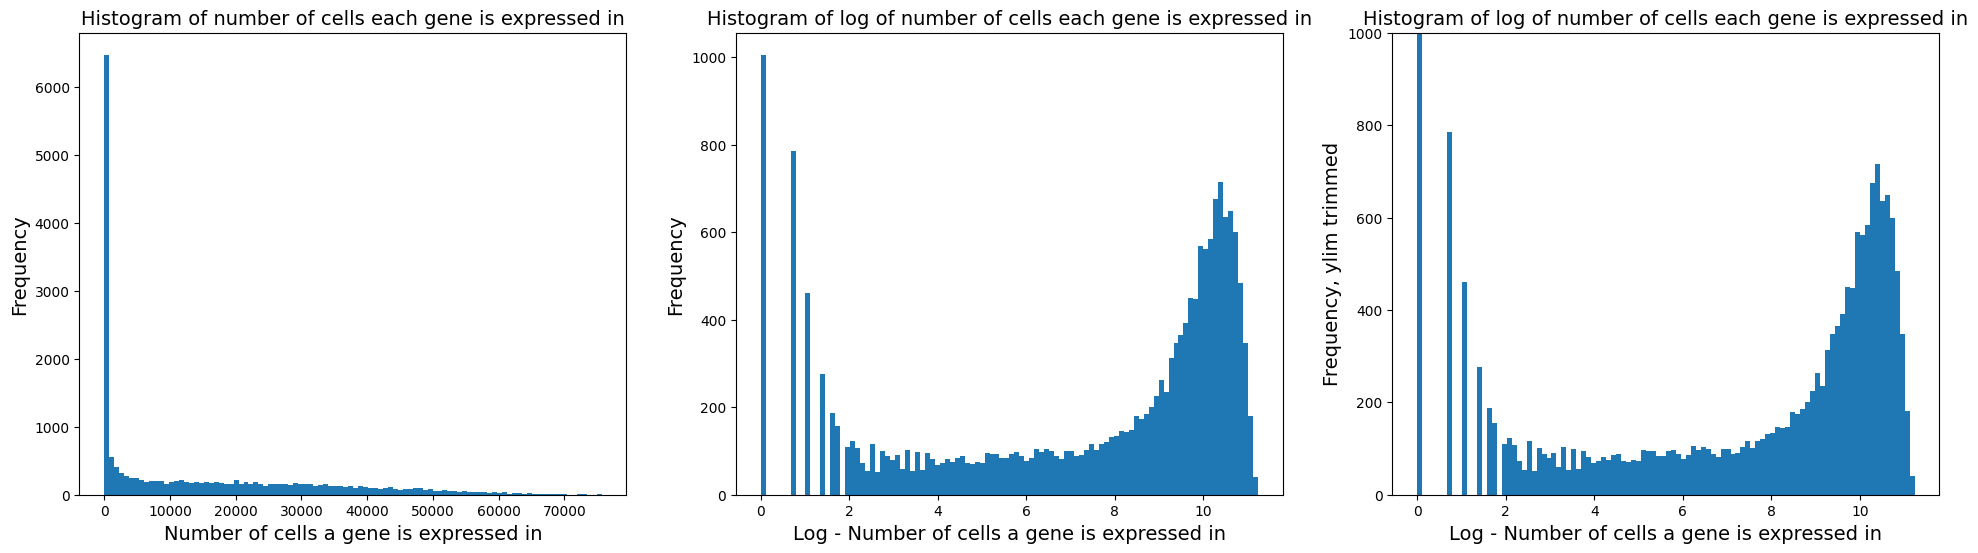

In [21]:
fig = plt.figure(figsize = (8*3, 6*1))
ax = fig.add_subplot(1, 3, 1)
ax.hist(adata.var['n_cells_by_counts'], bins = 100);
ax.set_xlabel('Number of cells a gene is expressed in', fontsize = 14)
ax.set_ylabel('Frequency', fontsize = 14)
ax.set_title('Histogram of number of cells each gene is expressed in', fontsize = 14)

ax = fig.add_subplot(1, 3, 2)
ax.hist(np.log(adata.var['n_cells_by_counts'] + 1), bins = 100);
ax.set_xlabel('Log - Number of cells a gene is expressed in', fontsize = 14)
ax.set_ylabel('Frequency', fontsize = 14)
ax.set_title('Histogram of log of number of cells each gene is expressed in', fontsize = 14)

ax = fig.add_subplot(1, 3, 3)
ax.hist(np.log(adata.var['n_cells_by_counts'] + 1), bins = 100);
ax.set_xlabel('Log - Number of cells a gene is expressed in', fontsize = 14)
ax.set_ylabel('Frequency, ylim trimmed', fontsize = 14)
ax.set_title('Histogram of log of number of cells each gene is expressed in', fontsize = 14)
ax.set_ylim([0, 1000])
(0.0, 1000.0)


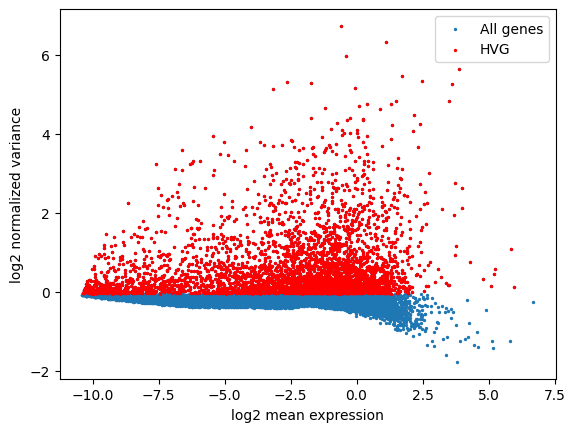

In [22]:
sc.pp.filter_genes(adata, min_cells = np.exp(4))
adata.layers['raw_data'] = adata.X.copy()
sc.pp.normalize_total(adata, inplace = True)
adata.layers['norm_counts'] = adata.X.copy()
adata.X = np.log2(adata.X.toarray() + 1)
adata.layers['zs_norm_log'] = scipy.stats.zscore(adata.X)
sc.pp.highly_variable_genes(adata, layer = 'raw_data', n_top_genes = 4000, flavor = 'seurat_v3')
adata.uns['id_hvg'] = np.where(adata.var['highly_variable'])[0]
x = np.log2(adata.var['means'])
y = np.log2(adata.var['variances_norm'])
plt.scatter(x, y, s = 2)
plt.scatter(x[adata.uns['id_hvg']], y[adata.uns['id_hvg']], s = 2, c = 'r')
plt.xlabel('log2 mean expression')
plt.ylabel('log2 normalized variance')
plt.legend(['All genes', 'HVG'])


Text(0, 0.5, '% Variance Explained')

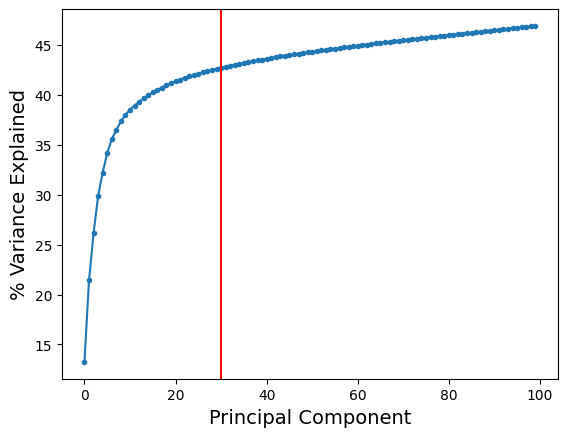

In [23]:
sc.tl.pca(adata, n_comps=100, use_highly_variable=True)
plt.plot(range(len(adata.uns['pca']['variance_ratio'])), np.cumsum(adata.uns['pca']['variance_ratio']) * 100, '.-')
plt.axvline(30, color = 'r')
plt.xlabel('Principal Component', fontsize = 14)
plt.ylabel('% Variance Explained', fontsize = 14)


In [24]:
n_PCs = 30
adata.obsm['X_pca'] = adata.obsm['X_pca'][:, 0:n_PCs]
adata.varm['PCs'] = adata.varm['PCs'][:, 0:n_PCs]
adata.uns['loadings'] = adata.varm['PCs'][adata.var['highly_variable'], :]
adata.uns['loadings'] = adata.uns['loadings'][:, 0:n_PCs]



In [25]:
sc.pp.neighbors(adata, n_neighbors=30, use_rep='X_pca', metric='euclidean', key_added='neighbors_30')
sc.tl.umap(adata, neighbors_key = 'neighbors_30', min_dist=0.1)


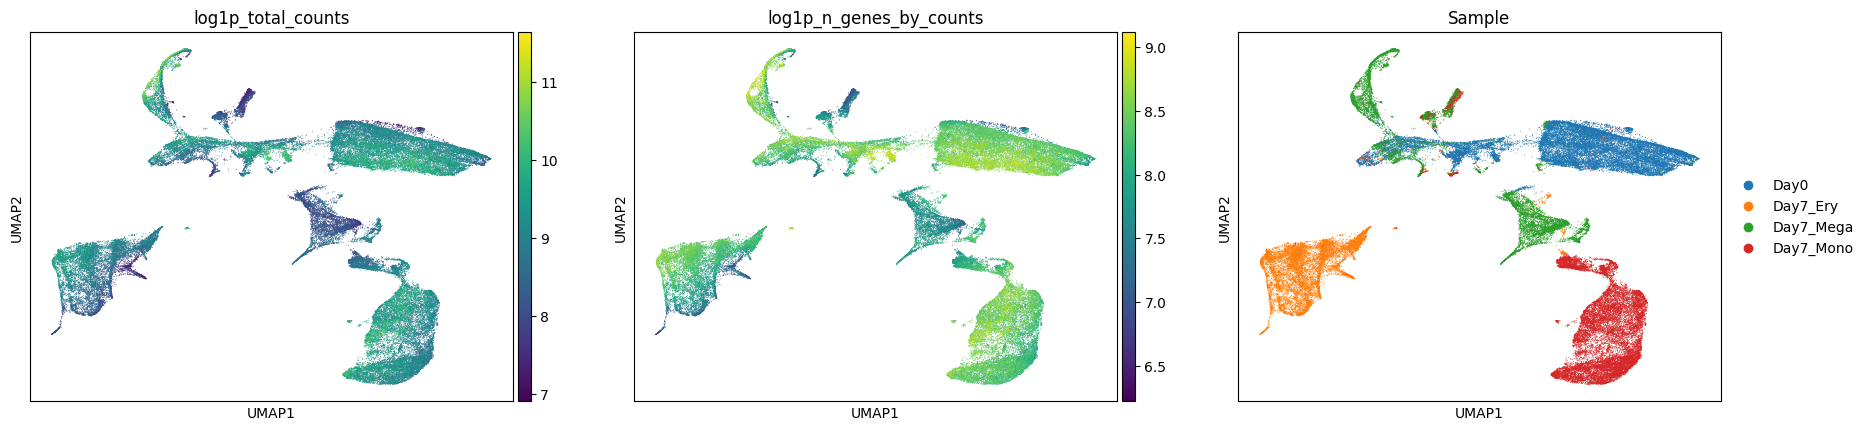

In [29]:
sc.pl.umap(adata, color = ['log1p_total_counts', 'log1p_n_genes_by_counts','Sample'], 
           cmap = 'viridis', ncols = 3)


Finding 200 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 0.8447608947753906 seconds
Jaccard graph constructed in 35.92273688316345 seconds
Running Leiden optimization
Leiden completed in 76.14207696914673 seconds
Sorting communities by size, please wait ...
PhenoGraph completed in 119.83442759513855 seconds


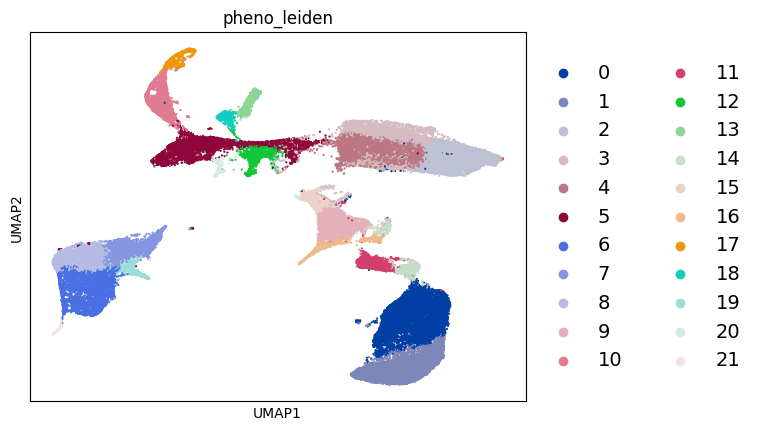

In [30]:
sc.external.tl.phenograph(adata, clustering_algo='leiden', k=200, jaccard=True, primary_metric='euclidean', 
                          resolution_parameter=1)
sc.pl.umap(adata, color = ['pheno_leiden'], s = 10, palette = sc.pl.palettes.zeileis_28, legend_fontsize = 14)


In [31]:
adata_scrublet = sc.AnnData(adata.layers['raw_data'], obs = adata.obs, var = adata.var)
sc.external.pp.scrublet(adata_scrublet, sim_doublet_ratio=2.0, expected_doublet_rate=0.06, 
                       knn_dist_metric='euclidean', log_transform=True, n_prin_comps=20, 
                       random_state=0)

adata.obs[['doublet_score', 'predicted_doublet']] = adata_scrublet.obs[['doublet_score', 'predicted_doublet']]
adata.uns['scrublet'] = adata_scrublet.uns['scrublet']


Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


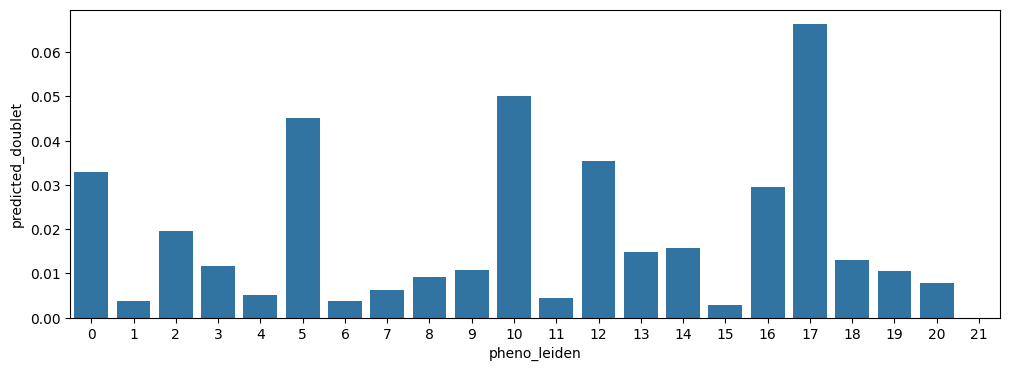

In [32]:
df_temp = adata.obs[['pheno_leiden', 'predicted_doublet']]

import seaborn as sns
fig = plt.figure(figsize = (12, 4))
ax = fig.add_subplot(1, 1, 1)
sns.barplot(x = 'pheno_leiden', y = 'predicted_doublet', data = df_temp, ax = ax, errorbar = None)

clusters_remove_doublet = df_temp.groupby('pheno_leiden')['predicted_doublet'].mean()[df_temp.groupby('pheno_leiden')['predicted_doublet'].mean() > 0.6].index


In [35]:
cells_remove = np.array(np.isin(adata.obs['pheno_leiden'], clusters_remove_doublet) | (adata.obs['predicted_doublet']))
print('removing ' + str(sum(cells_remove)) + ' cells')
adata_clean = sc.AnnData(adata.X[~cells_remove, :], 
                         obs = adata.obs.iloc[~cells_remove, :], 
                         var = adata.var)
adata_clean.layers['norm_counts'] = adata.layers['norm_counts'][~cells_remove, :].copy()
adata_clean.layers['raw_data'] = adata.layers['raw_data'][~cells_remove, :].copy()
adata_clean.layers['zs_norm_log'] = adata.layers['zs_norm_log'][~cells_remove, :].copy()


removing 1324 cells


In [36]:
adata = adata_clean.copy()

n_PCs = 30
sc.pp.highly_variable_genes(adata, layer = 'raw_data', n_top_genes = 4000, flavor = 'seurat_v3')
adata.uns['id_hvg'] = np.where(adata.var['highly_variable'])[0]
sc.tl.pca(adata, n_comps=100, use_highly_variable=True)

adata.obsm['X_pca'] = adata.obsm['X_pca'][:, 0:n_PCs]
adata.varm['PCs'] = adata.varm['PCs'][:, 0:n_PCs]
adata.uns['loadings'] = adata.varm['PCs'][adata.var['highly_variable'], :]
adata.uns['loadings'] = adata.uns['loadings'][:, 0:n_PCs]

sc.pp.neighbors(adata, n_neighbors=30, use_rep='X_pca', metric='euclidean', key_added='neighbors_30')
sc.tl.umap(adata, neighbors_key = 'neighbors_30', min_dist=0.1)

sc.external.tl.phenograph(adata, clustering_algo='leiden', k=200, jaccard=True, primary_metric='euclidean', 
                          resolution_parameter=1)

Finding 200 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 0.7448821067810059 seconds
Jaccard graph constructed in 55.52129793167114 seconds
Running Leiden optimization
Leiden completed in 79.39236354827881 seconds
Sorting communities by size, please wait ...
PhenoGraph completed in 146.61990809440613 seconds


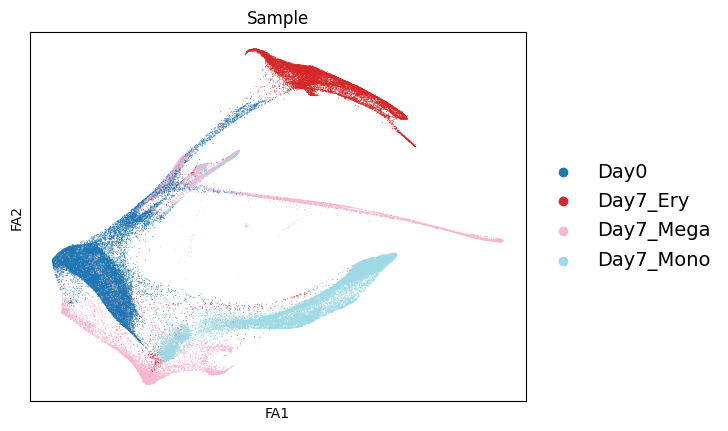

In [ ]:
sc.tl.draw_graph(adata, layout='fa', random_state=1, neighbors_key='neighbors_30')
sc.pl.draw_graph(adata, color='Sample', palette = 'tab20', legend_fontsize = 14,)

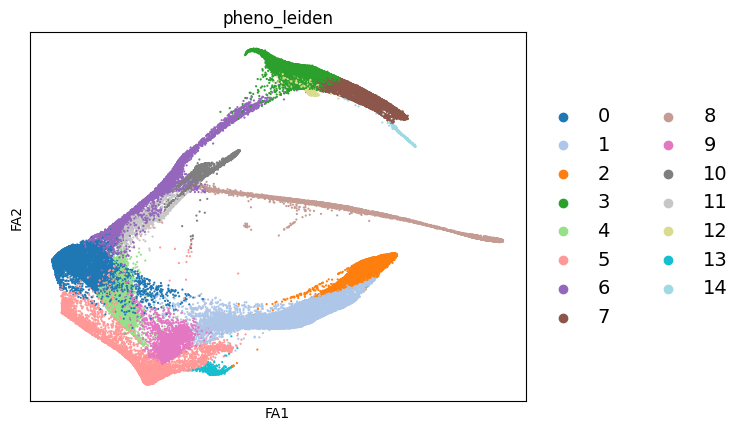

In [ ]:
sc.external.tl.phenograph(adata, clustering_algo='leiden', k=200, jaccard=True, primary_metric='euclidean', 
                          resolution_parameter=0.5)
sc.pl.draw_graph(adata, color = ['pheno_leiden'], s = 10, palette = 'tab20', legend_fontsize = 14)


In [40]:
run_MAGIC.run_MAGIC(adata, knn = 30, t = 3, use_rep = 'X_pca', neighbors_key = None, 
          layer = None, n_components = 30, metric = 'euclidean', key_added = 'magic_on_pca')

Using knn_affinity = 10
Computing nearest neighbor graph
Creating Kernel
Creating Markov Matrix
Imputing


AnnData object with n_obs × n_vars = 72601 × 13633
    obs: 'Sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mito_frac', 'PBMC_cell_types', 'n_counts', 'n_genes', 'pheno_leiden', 'doublet_score', 'predicted_doublet'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'n_cells'
    uns: 'hvg', 'id_hvg', 'pca', 'loadings', 'neighbors_30', 'umap', 'pheno_jaccard_q', 'pheno_leiden_colors', 'PBMC_cell_types_colors', 'Sample_colors', 'draw_graph', 'magic_on_pca_diffmap_results'
    obsm: 'X_pca', 'X_umap', 'X_draw_graph_fa'
    varm: 'PCs'
    layers: 'norm_counts', 'raw_data', 'zs_norm_log', 'magic_on_pca_imputed_data'
    obsp: 'neighbors_30_distances', 'neighbors_

🔬 Input data has 72601 cells and 13633 genes
🔗 Matching reference genes in the model
🧬 1704 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Can not detect a neighborhood graph, will construct one before the over-clustering
⛓️ Over-clustering input data with resolution set to 20
🗳️ Majority voting the predictions
✅ Majority voting done!


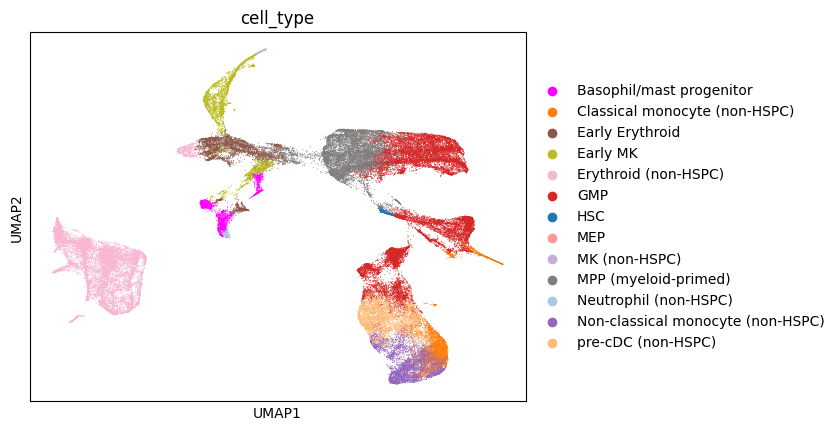

In [41]:
adata.X = adata.layers['raw_data'].copy()
sc.pp.normalize_total(adata, target_sum = 1e4)
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata, layer = 'raw_data', n_top_genes = 4000, flavor = 'seurat_v3')

sc.tl.pca(adata, n_comps=100, use_highly_variable=True)

# CellTypist prediction without over-clustering and majority-voting.
predictions = celltypist.annotate(adata, model = '/home/blattms1/.celltypist/data/models/model_from_MPN8_MPN18.pkl', majority_voting=True)
adata.obs['cell_type'] = predictions.predicted_labels['majority_voting']
adata.X = np.log2(adata.layers['norm_counts'].toarray() + 1)
sc.pl.umap(adata, color = 'cell_type', palette = cell_type_palette)


In [7]:
adata.write_h5ad('/data1/lareauc/users/blattms/gapfill/wta_adata/tRNA_HSC_differentiation.h5ad')
